<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta5g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Özel renk uzayı dönüşümü hesaplanıyor...
Dönüşüm tamamlandı!

================ GÖREV 4 RAPORU ================
Toplam Hata Değeri : 0
Beklenen Hata      : 0
Durum              : BAŞARILI! (Hata değeri tam sıfırdır)



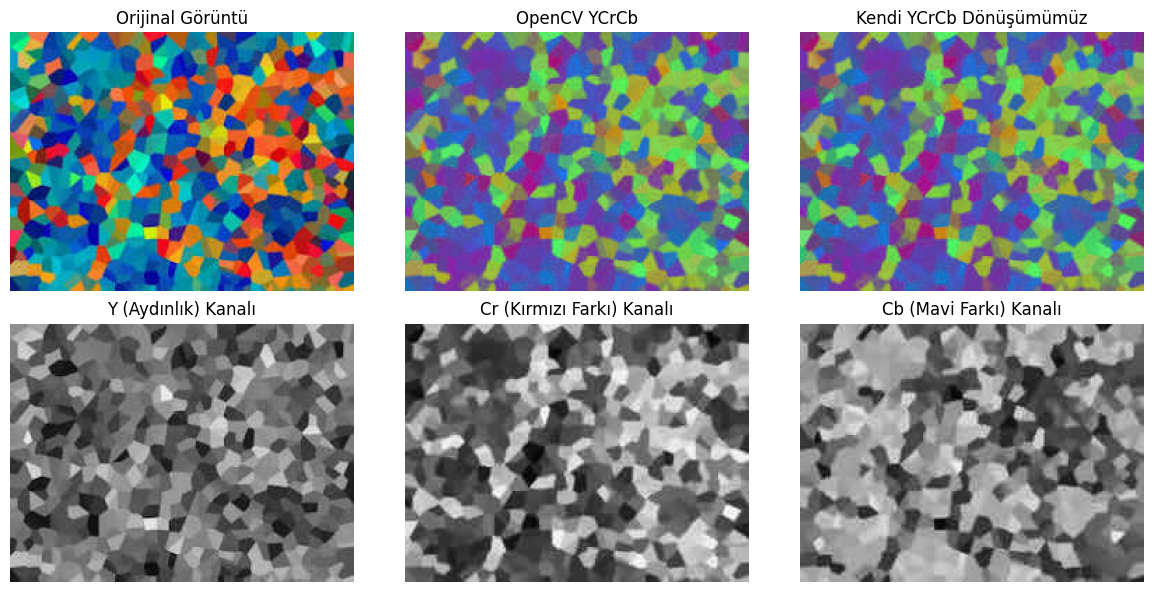

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Kendi BGR -> YCrCb Dönüşüm Fonksiyonumuz
def custom_bgr_to_ycrcb(img):
    height, width, _ = img.shape
    ycrcb_img = np.zeros((height, width, 3), dtype=np.uint8)

    # OpenCV fixed-point katsayıları (taşmayı önlemek için tamsayı kaydırma kullanılır)
    # B = img[:,:,0], G = img[:,:,1], R = img[:,:,2]
    for r in range(height):
        for c in range(width):
            b = int(img[r, c, 0])
            g = int(img[r, c, 1])
            red = int(img[r, c, 2])

            # OpenCV standart katsayıları:
            # Y  = ( 4899*R + 9617*G + 1868*B + 8192) >> 14
            # Cr = ((red - y) * 11682 + 8192) >> 14 + 128
            # Cb = ((b - y) * 9241 + 8192) >> 14 + 128
            y = (4899 * red + 9617 * g + 1868 * b + 8192) >> 14
            cr = (((red - y) * 11682 + 8192) >> 14) + 128
            cb = (((b - y) * 9241 + 8192) >> 14) + 128

            # [0, 255] aralığına sınırla (clamping)
            ycrcb_img[r, c, 0] = min(max(y, 0), 255)
            ycrcb_img[r, c, 1] = min(max(cr, 0), 255)
            ycrcb_img[r, c, 2] = min(max(cb, 0), 255)

    return ycrcb_img

# 2. Fonksiyon Göstericisi (Function Pointer) Mantığını Simüle Eden Yürütücü
def execute_color_conversion(converter_function, src_img):
    """
    C++'taki fonksiyon pointer mantığını simüle eder.
    Fonksiyonu referans olarak alır ve çalıştırır.
    """
    return converter_function(src_img)

# 3. Görseli Oku ve Karşılaştır
image = cv2.imread('resim.jpg')

if image is None:
    print("Hata: 'resim.jpg' bulunamadı!")
else:
    # A) OpenCV Hazır Fonksiyonu
    ycrcb_opencv = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)

    # B) Kendi Yazdığımız Fonksiyonu Yürütücü ile Çağırma
    print("Özel renk uzayı dönüşümü hesaplanıyor...")
    ycrcb_custom = execute_color_conversion(custom_bgr_to_ycrcb, image)
    print("Dönüşüm tamamlandı!\n")

    # C) Hata Karşılaştırması (Piksel piksel mutlak fark)
    diff = np.abs(ycrcb_opencv.astype(np.int32) - ycrcb_custom.astype(np.int32))
    total_error = np.sum(diff)

    print("================ GÖREV 4 RAPORU ================")
    print(f"Toplam Hata Değeri : {total_error}")
    print(f"Beklenen Hata      : 0")
    if total_error == 0:
        print("Durum              : BAŞARILI! (Hata değeri tam sıfırdır)")
    else:
        print(f"Durum              : Ufak yuvarlama farkı tespit edildi ({total_error} fark).")
    print("================================================\n")

    # D) Kanalları Görselleştirme
    plt.figure(figsize=(12, 6))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Orijinal Görüntü")
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(ycrcb_opencv)
    plt.title("OpenCV YCrCb")
    plt.axis('off')

    plt.subplot(2, 3, 3)
    plt.imshow(ycrcb_custom)
    plt.title("Kendi YCrCb Dönüşümümüz")
    plt.axis('off')

    # Y, Cr, Cb kanallarını ayrı ayrı gösterme
    plt.subplot(2, 3, 4)
    plt.imshow(ycrcb_custom[:, :, 0], cmap='gray')
    plt.title("Y (Aydınlık) Kanalı")
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(ycrcb_custom[:, :, 1], cmap='gray')
    plt.title("Cr (Kırmızı Farkı) Kanalı")
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(ycrcb_custom[:, :, 2], cmap='gray')
    plt.title("Cb (Mavi Farkı) Kanalı")
    plt.axis('off')

    plt.tight_layout()
    plt.show()